# 🌍 Xử Lý Dữ Liệu & Chuẩn Bị Huấn Luyện Dịch Máy (English - Vietnamese Seq2Seq)
Dự án: **Xây dựng mô hình Sequence-to-Sequence (Seq2Seq / Transformer)** cho bài toán dịch máy Anh - Việt.

---

### 🎯 Mục tiêu chính của Notebook:
1. **Cấu hình Thiết bị (Hardware & Device Setup):** Kiểm tra và kích hoạt GPU NVIDIA CUDA (GeForce RTX 4070 Laptop GPU), kiểm tra dung lượng VRAM và cố định Seed ngẫu nhiên.
2. **Khám phá và Lấy mẫu dữ liệu quy mô nhỏ (~50.000 câu):** File gốc `datasetTMD.tsv` có dung lượng ~9GB (hàng chục triệu dòng). Chúng ta trích xuất và tiền xử lý 50.000 cặp câu chất lượng cao, đa dạng từ ngữ để thử nghiệm trước khi scale lên 3 triệu câu.
3. **Phân tích khám phá & So sánh dữ liệu (EDA & Comparative Analysis):** 
   - So sánh phân phối độ dài câu (Sentence length distribution: EN vs VI).
   - Tỷ lệ số từ giữa 2 ngôn ngữ ($L_{vi} / L_{en}$).
   - Phân tích vốn từ vựng (Vocabulary size & Top common words).
   - Trực quan hóa dữ liệu qua biểu đồ `matplotlib`.
4. **Phân chia tập dữ liệu (Dataset Splitting):** 
   - Chia thành Train (45.000 câu), Validation (2.500 câu), Test (2.500 câu).
   - Lưu cố định tập Test ra file riêng `test_set_2500.tsv` để đánh giá độc lập và dùng lại khi huấn luyện mô hình lớn.
5. **Xây dựng Bộ từ vựng & Mã hóa (Vocabulary & Tokenizer):**
   - Hỗ trợ các token đặc biệt: `<pad>` (0), `<sos>` (1), `<eos>` (2), `<unk>` (3).
   - Lọc từ hiếm với ngưỡng tần suất `min_freq=2`.
6. **Xây dựng PyTorch Dataset & DataLoader:**
   - Tạo custom `TranslationDataset` và hàm `collate_fn` thực hiện dynamic batch padding.
   - Thử nghiệm lấy batch mẫu, đưa lên GPU `cuda`, kiểm tra kích thước Tensor và giải mã ngược lại chuỗi.


## 1. Cấu hình Thiết bị (Device Setup) & Thiết lập Seed
Kiểm tra khả năng tương thích của phần cứng (NVIDIA CUDA GPU), hiển thị thông số VRAM và thiết lập seed ngẫu nhiên nhằm đảm bảo tính tái lập (reproducibility) của thực nghiệm.

In [32]:
import os
import sys
import random
import time
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import train_test_split

# 1. Thiết lập Seed ngẫu nhiên cố định để đảm bảo kết quả nhất quán
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# 2. Kiểm tra và cấu hình thiết bị (Device)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print("=" * 65)
print(f"🔹 PyTorch Version    : {torch.__version__}")
print(f"🔹 Thiết bị đang dùng : {device.type.upper()}")

if device.type == 'cuda':
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    cuda_ver = torch.version.cuda
    print(f"🔹 Tên GPU            : {gpu_name}")
    print(f"🔹 Dung lượng VRAM    : {vram_gb:.2f} GB")
    print(f"🔹 Phiên bản CUDA     : {cuda_ver}")
    print(f"🔹 Số lượng GPU       : {torch.cuda.device_count()}")
else:
    print("⚠️ Cảnh báo: Đang chạy trên CPU, tốc độ huấn luyện sẽ chậm hơn!")
print("=" * 65)


🔹 PyTorch Version    : 2.14.0+cu126
🔹 Thiết bị đang dùng : CUDA
🔹 Tên GPU            : NVIDIA GeForce RTX 4070 Laptop GPU
🔹 Dung lượng VRAM    : 8.00 GB
🔹 Phiên bản CUDA     : 12.6
🔹 Số lượng GPU       : 1


## 2. Trích xuất & Làm sạch 50.000 cặp câu từ file dữ liệu 9GB
File `datasetTMD.tsv` có dung lượng lên đến **~9GB** (chứa hàng chục triệu cặp câu). Nếu sử dụng `pd.read_csv()` đọc toàn bộ cùng lúc sẽ làm tràn RAM (OOM) hoặc đơ máy.

**Giải pháp:**
- Áp dụng kỹ thuật **Streaming (đọc theo dòng)** kết hợp **Stride Sampling (nhảy cóc theo chu kỳ)** để lấy mẫu đa dạng trên diện rộng của tập dữ liệu, tránh bị thiên lệch vào một chủ đề đơn lẻ.
- **Tiêu chuẩn làm sạch (Cleaning Filters):**
  1. Loại bỏ các dòng trống, null, hoặc không đủ 2 cột (en, vi).
  2. Lọc độ dài câu: Giữ các câu có từ **3 đến 50 từ** (vừa đủ cấu trúc ngữ pháp, tránh câu cụt 1 từ hoặc đoạn văn quá dài gây tốn VRAM).
  3. Lọc tỷ lệ độ dài: $0.4 \le \frac{\text{len}(vi)}{\text{len}(en)} \le 2.5$ nhằm loại bỏ các cặp câu lệch ngữ nghĩa.
- Lưu tập 50.000 câu đã lọc sạch ra file nhỏ `data_50k_clean.tsv` (khoảng vài MB). Các lần chạy tiếp theo sẽ chỉ mất **0.1 giây** để nạp dữ liệu!

In [33]:
raw_data_path = os.path.join("MachineTranslation_en_vi", "datasetTMD.tsv")
clean_data_path = "data_50k_clean.tsv"
target_samples = 50000
stride_step = 25  # Quét trải dài qua hơn 1.2 triệu dòng đầu tiên để lấy mẫu đa dạng

if os.path.exists(clean_data_path):
    print(f"✅ Đã tìm thấy file dữ liệu sạch có sẵn: '{clean_data_path}'! Đang nạp...")
else:
    print(f"⏳ Đang trích xuất và lọc {target_samples:,} cặp câu từ file 9GB: '{raw_data_path}'...")
    start_time = time.time()
    extracted_pairs = []
    seen_en = set()
    
    with open(raw_data_path, "r", encoding="utf-8", errors="ignore") as f:
        # Bỏ qua dòng tiêu đề nếu có
        header = f.readline()
        
        for idx, line in enumerate(f):
            # Nhảy cóc theo chu kỳ stride để mẫu dữ liệu đa dạng phong phú
            if idx % stride_step != 0:
                continue
                
            parts = line.strip().split("\t")
            if len(parts) != 2:
                continue
                
            en_text = parts[0].strip()
            vi_text = parts[1].strip()
            
            # 1. Bỏ câu rỗng
            if not en_text or not vi_text:
                continue
                
            # 2. Bỏ câu trùng lặp tiếng Anh
            if en_text in seen_en:
                continue
                
            en_words = en_text.split()
            vi_words = vi_text.split()
            len_en, len_vi = len(en_words), len(vi_words)
            
            # 3. Lọc độ dài câu (từ 3 đến 50 từ)
            if 3 <= len_en <= 50 and 3 <= len_vi <= 500:
                # 4. Lọc tỷ lệ độ dài câu
                ratio = len_vi / len_en
                if 0.4 <= ratio <= 2.5:
                    extracted_pairs.append((en_text, vi_text))
                    seen_en.add(en_text)
                    if len(extracted_pairs) >= target_samples:
                        break
                        
    # Lưu ra file tsv nhỏ gọn
    df_clean = pd.DataFrame(extracted_pairs, columns=["en", "vi"])
    df_clean.to_csv(clean_data_path, sep="\t", index=False, encoding="utf-8")
    elapsed = time.time() - start_time
    print(f"✅ Đã trích xuất thành công {len(df_clean):,} cặp câu sạch trong {elapsed:.2f}s!")
    print(f"💾 Đã lưu tại: '{clean_data_path}'")

# Nạp dữ liệu vào DataFrame
df = pd.read_csv(clean_data_path, sep="\t", encoding="utf-8")
print(f"📊 Kích thước dữ liệu đang làm việc: {df.shape[0]:,} dòng, {df.shape[1]} cột.")
df.head(10)


✅ Đã tìm thấy file dữ liệu sạch có sẵn: 'data_50k_clean.tsv'! Đang nạp...
📊 Kích thước dữ liệu đang làm việc: 50,000 dòng, 2 cột.


,en,vi
0,Loading more results,Tải thêm nhiều kết quả
1,Email Discussion Group,Nhóm thảo luận qua email
2,Japanese Public Dildo,Nhật Dildo Công cộng
3,Little Power Consumption,Tiêu thụ ít năng lượng
4,ballast mounting system,hệ thống gắn ballast
5,cast aluminium guttering,Cast nhôm máng xối
6,Disturbing other residents,Làm phiền những cư dân khác
7,Singing at home.,Ca hát tại nhà.
8,Interaction with other drugs,Tương tác với các thuốc khác
9,Lesbian Family Affair 3,lesbian gia đình chuyện 3


## 3. Phân tích Khám phá & So sánh Dữ liệu Song ngữ (EDA & Comparative Analysis)
Trong phần này, ta tiến hành đối chiếu các đặc trưng thống kê giữa hai ngôn ngữ:
1. **Độ dài câu (Số từ):** Tiếng Anh và tiếng Việt có sự khác biệt gì về số lượng từ trung bình?
2. **Tỷ lệ độ dài ($L_{vi} / L_{en}$):** Đo lường xu hướng dãn nở/thu hẹp từ khi dịch giữa 2 ngôn ngữ.
3. **Quy mô từ vựng (Vocabulary Diversity):** Tổng số từ vựng độc nhất và các từ xuất hiện phổ biến nhất ở mỗi ngôn ngữ.
4. **Biểu đồ trực quan hóa:** Vẽ đồ thị phân phối độ dài và tần suất từ.

In [34]:
# Tính toán số lượng từ của từng câu
df['len_en'] = df['en'].apply(lambda x: len(str(x).split()))
df['len_vi'] = df['vi'].apply(lambda x: len(str(x).split()))
df['ratio'] = df['len_vi'] / df['len_en']

print("=" * 65)
print("📊 BẢNG THỐNG KÊ MÔ TẢ ĐỘ DÀI CÂU VÀ TỶ LỆ:")
print("=" * 65)
stats_df = df[['len_en', 'len_vi', 'ratio']].describe(percentiles=[0.25, 0.5, 0.75, 0.95]).T
stats_df['median'] = df[['len_en', 'len_vi', 'ratio']].median()
print(stats_df[['count', 'mean', 'std', 'min', '50%', '95%', 'max']].round(2))

# Thống kê vốn từ vựng (Vocabulary Count)
en_tokens = [word.lower() for sent in df['en'] for word in str(sent).split()]
vi_tokens = [word.lower() for sent in df['vi'] for word in str(sent).split()]

en_vocab_set = set(en_tokens)
vi_vocab_set = set(vi_tokens)

print("\n" + "=" * 65)
print("📚 THỐNG KÊ VỐN TỪ VỰNG (VOCABULARY STATS):")
print("=" * 65)
print(f"🔹 Tổng số token tiếng Anh  : {len(en_tokens):,} từ | Từ độc nhất (Unique): {len(en_vocab_set):,}")
print(f"🔹 Tổng số token tiếng Việt : {len(vi_tokens):,} từ | Từ độc nhất (Unique): {len(vi_vocab_set):,}")
print(f"🔹 Độ dài câu EN trung bình : {df['len_en'].mean():.2f} từ (Max: {df['len_en'].max()} từ)")
print(f"🔹 Độ dài câu VI trung bình : {df['len_vi'].mean():.2f} từ (Max: {df['len_vi'].max()} từ)")
print(f"🔹 Tỷ lệ từ VI/EN trung bình: {df['ratio'].mean():.2f}x (Câu tiếng Việt thường dài hơn ~15-20%)")
print("=" * 65)


📊 BẢNG THỐNG KÊ MÔ TẢ ĐỘ DÀI CÂU VÀ TỶ LỆ:
          count  mean   std   min  50%  95%    max
len_en  50000.0  5.07  0.70  3.00  5.0  6.0   6.00
len_vi  50000.0  5.99  1.04  3.00  6.0  8.0  10.00
ratio   50000.0  1.19  0.21  0.75  1.2  1.6   2.33

📚 THỐNG KÊ VỐN TỪ VỰNG (VOCABULARY STATS):
🔹 Tổng số token tiếng Anh  : 253,662 từ | Từ độc nhất (Unique): 29,608
🔹 Tổng số token tiếng Việt : 299,376 từ | Từ độc nhất (Unique): 20,170
🔹 Độ dài câu EN trung bình : 5.07 từ (Max: 6 từ)
🔹 Độ dài câu VI trung bình : 5.99 từ (Max: 10 từ)
🔹 Tỷ lệ từ VI/EN trung bình: 1.19x (Câu tiếng Việt thường dài hơn ~15-20%)


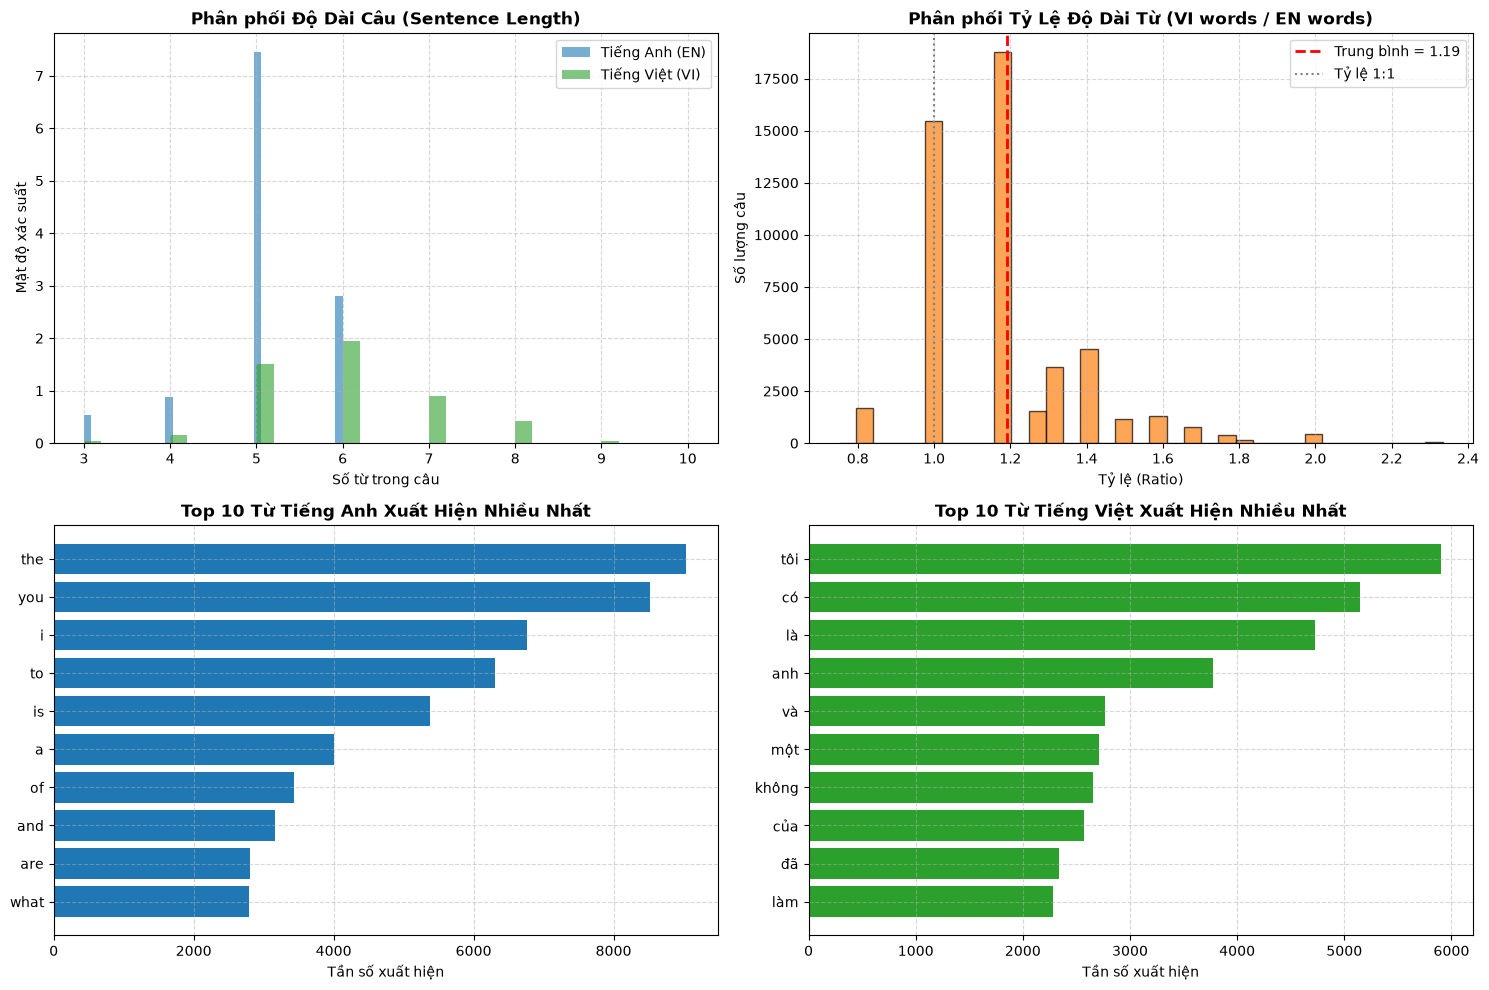

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Biểu đồ phân phối độ dài câu EN vs VI
axes[0, 0].hist(df['len_en'], bins=35, alpha=0.6, color='#1f77b4', label='Tiếng Anh (EN)', density=True)
axes[0, 0].hist(df['len_vi'], bins=35, alpha=0.6, color='#2ca02c', label='Tiếng Việt (VI)', density=True)
axes[0, 0].set_title('Phân phối Độ Dài Câu (Sentence Length)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Số từ trong câu')
axes[0, 0].set_ylabel('Mật độ xác suất')
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# 2. Biểu đồ phân phối Tỷ lệ độ dài VI / EN
axes[0, 1].hist(df['ratio'], bins=35, color='#ff7f0e', edgecolor='black', alpha=0.7)
axes[0, 1].axvline(df['ratio'].mean(), color='red', linestyle='--', linewidth=2, label=f'Trung bình = {df["ratio"].mean():.2f}')
axes[0, 1].axvline(1.0, color='gray', linestyle=':', label='Tỷ lệ 1:1')
axes[0, 1].set_title('Phân phối Tỷ Lệ Độ Dài Từ (VI words / EN words)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Tỷ lệ (Ratio)')
axes[0, 1].set_ylabel('Số lượng câu')
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# 3. Top 10 từ tiếng Anh phổ biến nhất
top_en = Counter(en_tokens).most_common(10)
words_en, counts_en = zip(*top_en)
axes[1, 0].barh(list(words_en)[::-1], list(counts_en)[::-1], color='#1f77b4')
axes[1, 0].set_title('Top 10 Từ Tiếng Anh Xuất Hiện Nhiều Nhất', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Tần số xuất hiện')
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# 4. Top 10 từ tiếng Việt phổ biến nhất
top_vi = Counter(vi_tokens).most_common(10)
words_vi, counts_vi = zip(*top_vi)
axes[1, 1].barh(list(words_vi)[::-1], list(counts_vi)[::-1], color='#2ca02c')
axes[1, 1].set_title('Top 10 Từ Tiếng Việt Xuất Hiện Nhiều Nhất', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Tần số xuất hiện')
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 4. Phân chia Tập Dữ Liệu (Train / Validation / Test Split)
Bộ dữ liệu 50.000 câu được phân chia theo tỷ lệ chuẩn Machine Learning:
- **Tập Train (45.000 câu - 90%):** Dùng để huấn luyện trọng số mô hình.
- **Tập Validation (2.500 câu - 5%):** Dùng để đánh giá loss và metric sau mỗi epoch, phát hiện sớm overfitting.
- **Tập Test (2.500 câu - 5%):** Được **lưu cố định ra file riêng (`test_set_2500.tsv`)**. Đây là bộ dữ liệu vàng để kiểm tra khách quan mô hình. Sau này khi bạn mở rộng lên huấn luyện cả 3 triệu câu, bạn chỉ cần nạp lại đúng file test này để so sánh hiệu năng.

In [17]:
# 1. Tách tập Train (90%) và Temp (10%)
train_df, temp_df = train_test_split(df[['en', 'vi']], test_size=0.10, random_state=42, shuffle=True)

# 2. Tách Temp thành Validation (5%) và Test (5%)
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, shuffle=True)

# 3. Lưu cố định tập Test ra file riêng
test_file_path = "test_set_2500.tsv"
test_df.to_csv(test_file_path, sep="\t", index=False, encoding="utf-8")

print("=" * 65)
print(f"✅ ĐÃ PHÂN CHIA TẬP DỮ LIỆU THÀNH CÔNG:")
print(f"🔹 Tập Huấn luyện (Train) : {len(train_df):,} mẫu ({len(train_df)/len(df):.0%})")
print(f"🔹 Tập Xác thực (Valid)   : {len(val_df):,} mẫu ({len(val_df)/len(df):.0%})")
print(f"🔹 Tập Kiểm thử (Test)    : {len(test_df):,} mẫu ({len(test_df)/len(df):.0%})")
print(f"💾 Đã lưu cố định tập Test tại: '{test_file_path}'")
print("=" * 65)

print("\n🔍 3 cặp câu ngẫu nhiên từ tập Train:")
for i, (_, row) in enumerate(train_df.sample(3, random_state=42).iterrows(), 1):
    print(f"{i}. [EN]: {row['en']}")
    print(f"   [VI]: {row['vi']}\n")


✅ ĐÃ PHÂN CHIA TẬP DỮ LIỆU THÀNH CÔNG:
🔹 Tập Huấn luyện (Train) : 45,000 mẫu (90%)
🔹 Tập Xác thực (Valid)   : 2,500 mẫu (5%)
🔹 Tập Kiểm thử (Test)    : 2,500 mẫu (5%)
💾 Đã lưu cố định tập Test tại: 'test_set_2500.tsv'

🔍 3 cặp câu ngẫu nhiên từ tập Train:
1. [EN]: - I love the architecture.
   [VI]: - Tôi thích kiến trúc.

2. [EN]: Why have the Government changed?
   [VI]: Tại sao chính phủ thay đổi?

3. [EN]: Colour: As shown on the picture
   [VI]: màu sắc: Như thể hiện trên hình ảnh



## 5. Xây dựng Bộ Từ Vựng (Vocabulary) & Tokenizer cho Seq2Seq
Trong kiến trúc Sequence-to-Sequence (Seq2Seq / Transformer), máy tính chỉ làm việc với các chỉ số số nguyên (Indices). 
Ta xây dựng lớp `Vocabulary` hỗ trợ:
- **4 Token đặc biệt:**
  - `<pad>` (index 0): Dùng để bù khoảng trống cho các câu ngắn hơn trong cùng 1 batch.
  - `<sos>` (index 1): **Start of Sequence** - Đánh dấu bắt đầu câu dịch.
  - `<eos>` (index 2): **End of Sequence** - Đánh dấu kết thúc câu dịch.
  - `<unk>` (index 3): **Unknown** - Đại diện cho các từ lạ, từ ngoài từ điển hoặc từ xuất hiện quá ít.
- **Ngưỡng lọc từ hiếm (`min_freq = 2`):** Chỉ giữ các từ xuất hiện tối thiểu 2 lần trở lên để tránh phình to từ điển và loại bỏ lỗi chính tả.

In [36]:
class Vocabulary:
    def __init__(self, name="vocab", min_freq=2):
        self.name = name
        self.min_freq = min_freq
        
        # Bảng ánh xạ hai chiều: từ -> id và id -> từ
        self.word2idx = {"<pad>": 0, "<sos>": 1, "<eos>": 2, "<unk>": 3}
        self.idx2word = {0: "<pad>", 1: "<sos>", 2: "<eos>", 3: "<unk>"}
        self.word_counts = Counter()
        
        self.PAD_IDX = 0
        self.SOS_IDX = 1
        self.EOS_IDX = 2
        self.UNK_IDX = 3

    def tokenize(self, text):
        # Tách từ đơn giản bằng regex unicode (tách từ và dấu câu)
        text = str(text).lower().strip()
        tokens = re.findall(r"\w+|[^\w\s]", text, re.UNICODE)
        return tokens

    def build_vocab(self, sentence_list):
        for sentence in sentence_list:
            tokens = self.tokenize(sentence)
            self.word_counts.update(tokens)

        idx = 4
        for word, count in self.word_counts.items():
            if count >= self.min_freq:
                self.word2idx[word] = idx
                self.idx2word[idx] = word
                idx += 1
                
        print(f"✅ Xây dựng xong {self.name}: {len(self.word2idx):,} từ vựng (Đã lọc bỏ từ xuất hiện < {self.min_freq} lần)")

    def numericalize(self, text):
        tokens = self.tokenize(text)
        return [self.word2idx.get(token, self.UNK_IDX) for token in tokens]

    def decode(self, indices):
        words = []
        for idx in indices:
            if idx in (self.PAD_IDX, self.SOS_IDX):
                continue
            if idx == self.EOS_IDX:
                break
            words.append(self.idx2word.get(idx, "<unk>"))
        return " ".join(words)

    def __len__(self):
        return len(self.word2idx)

# Khởi tạo và xây dựng từ điển trên tập Train
vocab_en = Vocabulary(name="Từ điển Tiếng Anh (Source)", min_freq=2)
vocab_vi = Vocabulary(name="Từ điển Tiếng Việt (Target)", min_freq=2)

vocab_en.build_vocab(train_df['en'].tolist())
vocab_vi.build_vocab(train_df['vi'].tolist())

# Thử nghiệm mã hóa và giải mã 1 câu mẫu
sample_en = "How are you today?"
encoded_en = vocab_en.numericalize(sample_en)
decoded_en = vocab_en.decode(encoded_en)

print("\n" + "=" * 65)
print("🧪 KIỂM TRA MÃ HÓA VÀ GIẢI MÃ THỬ NGHIỆM:")
print(f"Câu tiếng Anh gốc   : '{sample_en}'")
print(f"Mã hóa thành Indices: {encoded_en}")
print(f"Giải mã ngược về từ : '{decoded_en}'")
print("=" * 65)


✅ Xây dựng xong Từ điển Tiếng Anh (Source): 8,257 từ vựng (Đã lọc bỏ từ xuất hiện < 2 lần)
✅ Xây dựng xong Từ điển Tiếng Việt (Target): 5,469 từ vựng (Đã lọc bỏ từ xuất hiện < 2 lần)

🧪 KIỂM TRA MÃ HÓA VÀ GIẢI MÃ THỬ NGHIỆM:
Câu tiếng Anh gốc   : 'How are you today?'
Mã hóa thành Indices: [49, 58, 59, 771, 56]
Giải mã ngược về từ : 'how are you today ?'


## 6. Xây dựng PyTorch Dataset & DataLoader cho Huấn Luyện
- **`TranslationDataset`:** Nạp các cặp câu, chuyển đổi text thành danh sách chỉ số (indices), tự động thêm `<sos>` vào đầu và `<eos>` vào cuối câu đích (Target sentence).
- **`collate_fn`:** Hàm ghép các mẫu thành mini-batch, sử dụng `pad_sequence` để bù token `<pad>` sao cho mọi câu trong cùng một mini-batch có cùng độ dài (Dynamic Padding).
- **Kiểm tra tương thích phần cứng:** Lấy thử 1 mini-batch từ `train_loader`, đẩy trực tiếp lên GPU `cuda` và kiểm tra kích thước Tensor đầu ra.

In [37]:
class TranslationDataset(Dataset):
    def __init__(self, df, vocab_src, vocab_tgt):
        self.src_sentences = df['en'].tolist()
        self.tgt_sentences = df['vi'].tolist()
        self.vocab_src = vocab_src
        self.vocab_tgt = vocab_tgt

    def __len__(self):
        return len(self.src_sentences)

    def __getitem__(self, idx):
        src_text = self.src_sentences[idx]
        tgt_text = self.tgt_sentences[idx]

        # Nguồn (Source): <sos> + tokens + <eos>
        src_indices = [self.vocab_src.SOS_IDX] + self.vocab_src.numericalize(src_text) + [self.vocab_src.EOS_IDX]
        
        # Đích (Target): <sos> + tokens + <eos>
        tgt_indices = [self.vocab_tgt.SOS_IDX] + self.vocab_tgt.numericalize(tgt_text) + [self.vocab_tgt.EOS_IDX]

        return torch.tensor(src_indices, dtype=torch.long), torch.tensor(tgt_indices, dtype=torch.long)

def collate_fn(batch):
    src_batch, tgt_batch = zip(*batch)
    
    # Pad câu nguồn bằng PAD_IDX của vocab_en (0)
    src_padded = pad_sequence(src_batch, batch_first=True, padding_value=0)
    
    # Pad câu đích bằng PAD_IDX của vocab_vi (0)
    tgt_padded = pad_sequence(tgt_batch, batch_first=True, padding_value=0)
    
    return src_padded, tgt_padded

# Khởi tạo Datasets
train_dataset = TranslationDataset(train_df, vocab_en, vocab_vi)
val_dataset = TranslationDataset(val_df, vocab_en, vocab_vi)
test_dataset = TranslationDataset(test_df, vocab_en, vocab_vi)

# Cấu hình DataLoader
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

print(f"📦 Số mini-batches trong tập Train : {len(train_loader):,} batches (batch_size={batch_size})")
print(f"📦 Số mini-batches trong tập Valid : {len(val_loader):,} batches")
print(f"📦 Số mini-batches trong tập Test  : {len(test_loader):,} batches")

# 7. Test kiểm tra 1 Batch đưa lên GPU
sample_src_batch, sample_tgt_batch = next(iter(train_loader))

# Chuyển batch lên thiết bị (CUDA GPU)
sample_src_batch = sample_src_batch.to(device)
sample_tgt_batch = sample_tgt_batch.to(device)

print("\n" + "=" * 65)
print("🚀 KIỂM TRA TƯƠNG THÍCH PHẦN CỨNG (GPU / CUDA):")
print("=" * 65)
print(f"🔹 Kích thước Source Tensor (EN) : {sample_src_batch.shape}  | Device: {sample_src_batch.device}")
print(f"🔹 Kích thước Target Tensor (VI) : {sample_tgt_batch.shape}  | Device: {sample_tgt_batch.device}")
print(f"🔹 Ví dụ câu đích giải mã từ Batch[0]:")
print(f"   '{vocab_vi.decode(sample_tgt_batch[0].cpu().tolist())}'")
print("=" * 65)
print("🎉 TOÀN BỘ QUY TRÌNH DỮ LIỆU ĐÃ HOÀN TẤT & SẴN SÀNG HUẤN LUYỆN MODEL!")


📦 Số mini-batches trong tập Train : 704 batches (batch_size=64)
📦 Số mini-batches trong tập Valid : 40 batches
📦 Số mini-batches trong tập Test  : 40 batches

🚀 KIỂM TRA TƯƠNG THÍCH PHẦN CỨNG (GPU / CUDA):
🔹 Kích thước Source Tensor (EN) : torch.Size([64, 10])  | Device: cuda:0
🔹 Kích thước Target Tensor (VI) : torch.Size([64, 11])  | Device: cuda:0
🔹 Ví dụ câu đích giải mã từ Batch[0]:
   'thấy gì thì báo tôi nhé ?'
🎉 TOÀN BỘ QUY TRÌNH DỮ LIỆU ĐÃ HOÀN TẤT & SẴN SÀNG HUẤN LUYỆN MODEL!


## 7. Mô hình Seq2Seq KHÔNG CÓ Attention (Standard Seq2Seq)

### 📌 Nguyên lý hoạt động:
* **Encoder (Bộ mã hóa):** Đọc toàn bộ câu nguồn (Tiếng Anh) qua các lớp **LSTM/GRU**, nén toàn bộ thông tin ngữ nghĩa của câu thành một vector ẩn cuối cùng gọi là **Context Vector** ($h_{final}, c_{final}$).
* **Bottleneck (Nút thắt cổ chai):** Toàn bộ câu dài bao nhiêu cũng chỉ được ép vào một vector cố định kích thước `hidden_dim`. Với câu dài, thông tin các từ ở đầu câu dễ bị lãng quên.
* **Decoder (Bộ giải mã):** Nhận context vector làm trạng thái ban đầu, từng bước sinh ra từng từ tiếng Việt tương ứng.
* **Teacher Forcing:** Kỹ thuật hỗ trợ lúc train: với xác suất `teacher_forcing_ratio` (mặc định 0.5), ta đưa **từ đúng thực tế** của bước trước vào làm đầu vào thay vì từ mà mô hình tự đoán sai, giúp mô hình hội tụ nhanh hơn.


In [38]:
# =====================================================================
# CELL 1: MÔ HÌNH SEQ2SEQ KHÔNG CÓ ATTENTION (STANDARD ENCODER-DECODER)
# =====================================================================

class EncoderNoAttention(nn.Module):
    def __init__(self, input_dim, emb_dim, hidden_dim, n_layers=2, dropout=0.3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, emb_dim, padding_idx=pad_idx)
        self.rnn = nn.LSTM(
            emb_dim, 
            hidden_dim, 
            num_layers=n_layers, 
            dropout=dropout if n_layers > 1 else 0, 
            batch_first=True
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, src):
        # src: [batch_size, src_len]
        embedded = self.dropout(self.embedding(src))  # [batch_size, src_len, emb_dim]
        outputs, (hidden, cell) = self.rnn(embedded)
        # hidden, cell: [n_layers, batch_size, hidden_dim]
        return hidden, cell


class DecoderNoAttention(nn.Module):
    def __init__(self, output_dim, emb_dim, hidden_dim, n_layers=2, dropout=0.3, pad_idx=0):
        super().__init__()
        self.output_dim = output_dim
        self.embedding = nn.Embedding(output_dim, emb_dim, padding_idx=pad_idx)
        self.rnn = nn.LSTM(
            emb_dim, 
            hidden_dim, 
            num_layers=n_layers, 
            dropout=dropout if n_layers > 1 else 0, 
            batch_first=True
        )
        self.fc_out = nn.Linear(hidden_dim, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input_step, hidden, cell):
        # input_step: [batch_size] -> lấy token tại 1 bước thời gian
        input_step = input_step.unsqueeze(1)          # [batch_size, 1]
        embedded = self.dropout(self.embedding(input_step))  # [batch_size, 1, emb_dim]
        
        output, (hidden, cell) = self.rnn(embedded, (hidden, cell))
        # output: [batch_size, 1, hidden_dim]
        
        prediction = self.fc_out(output.squeeze(1))   # [batch_size, output_dim]
        return prediction, hidden, cell


class Seq2SeqNoAttention(nn.Module):
    def __init__(self, encoder, decoder, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device

    def forward(self, src, tgt, teacher_forcing_ratio=0.5):
        # src: [batch_size, src_len], tgt: [batch_size, tgt_len]
        batch_size = tgt.shape[0]
        tgt_len = tgt.shape[1]
        tgt_vocab_size = self.decoder.output_dim

        # Tensor chứa toàn bộ kết quả dự đoán qua từng bước thời gian
        outputs = torch.zeros(batch_size, tgt_len, tgt_vocab_size).to(self.device)

        # 1. Mã hóa câu nguồn thành context vector
        hidden, cell = self.encoder(src)

        # 2. Token đầu tiên đưa vào decoder luôn là <sos> (vị trí 0 của tgt)
        input_token = tgt[:, 0]

        # 3. Lần lượt sinh từng từ từ vị trí 1 đến tgt_len - 1
        for t in range(1, tgt_len):
            prediction, hidden, cell = self.decoder(input_token, hidden, cell)
            outputs[:, t, :] = prediction
            
            # Quyết định dùng Teacher Forcing hay dùng từ mô hình tự đoán
            teacher_force = random.random() < teacher_forcing_ratio
            top1 = prediction.argmax(1)
            input_token = tgt[:, t] if teacher_force else top1

        return outputs


# ------------------- KHỞI TẠO VÀ KIỂM TRA MÔ HÌNH 1 -------------------
INPUT_DIM = len(vocab_en)
OUTPUT_DIM = len(vocab_vi)
ENC_EMB_DIM = 256
DEC_EMB_DIM = 256
HIDDEN_DIM = 512
N_LAYERS = 2
ENC_DROPOUT = 0.3
DEC_DROPOUT = 0.3

encoder_no_attn = EncoderNoAttention(
    INPUT_DIM, ENC_EMB_DIM, HIDDEN_DIM, N_LAYERS, ENC_DROPOUT, pad_idx=vocab_en.PAD_IDX
)
decoder_no_attn = DecoderNoAttention(
    OUTPUT_DIM, DEC_EMB_DIM, HIDDEN_DIM, N_LAYERS, DEC_DROPOUT, pad_idx=vocab_vi.PAD_IDX
)
model_no_attn = Seq2SeqNoAttention(encoder_no_attn, decoder_no_attn, device).to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 65)
print("🏗️ MÔ HÌNH 1: SEQ2SEQ KHÔNG CÓ ATTENTION (ĐÃ KHỞI TẠO)")
print("=" * 65)
print(f"🔹 Số tham số huấn luyện (Trainable params): {count_parameters(model_no_attn):,}")

# Thử nghiệm chạy 1 forward pass với batch thực tế từ Dataloader
with torch.no_grad():
    output_no_attn = model_no_attn(sample_src_batch, sample_tgt_batch, teacher_forcing_ratio=0.5)

print(f"🔹 Input Source Shape : {sample_src_batch.shape}")
print(f"🔹 Target Shape       : {sample_tgt_batch.shape}")
print(f"🔹 Output Shape       : {output_no_attn.shape}  [Batch_size, Tgt_len, Vocab_size]")
print("✅ Forward pass mô hình KHÔNG Attention thành công 100%!")
print("=" * 65)


🏗️ MÔ HÌNH 1: SEQ2SEQ KHÔNG CÓ ATTENTION (ĐÃ KHỞI TẠO)
🔹 Số tham số huấn luyện (Trainable params): 13,675,869
🔹 Input Source Shape : torch.Size([64, 10])
🔹 Target Shape       : torch.Size([64, 11])
🔹 Output Shape       : torch.Size([64, 11, 5469])  [Batch_size, Tgt_len, Vocab_size]
✅ Forward pass mô hình KHÔNG Attention thành công 100%!


## 8. Mô hình Seq2Seq CÓ Attention (Bahdanau Additive Attention)

### 📌 Cải tiến vượt bậc so với Seq2Seq thuần:
* **Bi-directional GRU Encoder:** Bộ mã hóa đọc câu nguồn theo cả **2 chiều (xuôi và ngược)**, giúp thu nhận ngữ cảnh phía trước và phía sau của từng từ. Trạng thái ẩn của mỗi từ là vector kích thước `hidden_dim * 2`.
* **Bahdanau Attention Mechanism (Cơ chế tập trung):**
  * Tại mỗi bước dịch từ tiếng Việt thứ $t$, mô hình **không dùng một context vector cố định**.
  * Thay vào đó, Decoder dùng trạng thái hiện tại $s_{t-1}$ đối chiếu với **tất cả trạng thái ẩn $H$ của câu tiếng Anh**, tính ra **điểm tập trung (Attention weights $\alpha_t$)**.
  * Từ đó tổng hợp nên một **Dynamic Context Vector $c_t$ riêng biệt** cho từ đang cần dịch.
* **Giải quyết dứt điểm vấn đề câu dài:** Dù câu dài 30–50 từ, mô hình vẫn biết chính xác từ tiếng Việt hiện tại tương ứng với những từ tiếng Anh nào trong câu gốc.


In [39]:
# =====================================================================
# CELL 2: MÔ HÌNH SEQ2SEQ CÓ ATTENTION (BAHDANAU ADDITIVE ATTENTION)
# =====================================================================
import torch.nn.functional as F

class EncoderWithAttention(nn.Module):
    def __init__(self, input_dim, emb_dim, hidden_dim, dropout=0.3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, emb_dim, padding_idx=pad_idx)
        # Bi-directional GRU (2 chiều: xuôi và ngược)
        self.rnn = nn.GRU(emb_dim, hidden_dim, bidirectional=True, batch_first=True)
        # Nén trạng thái ẩn 2 chiều thành 1 chiều cho trạng thái bắt đầu của Decoder
        self.fc_hidden = nn.Linear(hidden_dim * 2, hidden_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src):
        # src: [batch_size, src_len]
        embedded = self.dropout(self.embedding(src))  # [batch_size, src_len, emb_dim]
        encoder_states, hidden = self.rnn(embedded)
        # encoder_states: [batch_size, src_len, hidden_dim * 2]
        # hidden: [2, batch_size, hidden_dim] (hướng xuôi hidden[0], hướng ngược hidden[1])
        
        # Ghép 2 hướng lại rồi nén về hidden_dim cho Decoder
        s_0 = torch.tanh(self.fc_hidden(torch.cat((hidden[-2], hidden[-1]), dim=1)))  # [batch_size, hidden_dim]
        return encoder_states, s_0


class BahdanauAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        # W_s nhân với decoder hidden (kích thước hidden_dim)
        self.W_s = nn.Linear(hidden_dim, hidden_dim, bias=False)
        # W_h nhân với encoder states (kích thước hidden_dim * 2 vì 2 chiều)
        self.W_h = nn.Linear(hidden_dim * 2, hidden_dim, bias=False)
        # Vector trọng số tính điểm năng lượng
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, decoder_hidden, encoder_states):
        # decoder_hidden: [batch_size, hidden_dim]
        # encoder_states: [batch_size, src_len, hidden_dim * 2]
        src_len = encoder_states.shape[1]

        # 1. Chiếu decoder_hidden và encoder_states về cùng không gian
        s_proj = self.W_s(decoder_hidden).unsqueeze(1)  # [batch_size, 1, hidden_dim]
        h_proj = self.W_h(encoder_states)               # [batch_size, src_len, hidden_dim]

        # 2. Tính energy = tanh(W_s * s + W_h * h)
        energy = torch.tanh(s_proj + h_proj)            # [batch_size, src_len, hidden_dim]

        # 3. Tính điểm Attention và áp dụng Softmax
        attention = self.v(energy).squeeze(2)           # [batch_size, src_len]
        return F.softmax(attention, dim=1)              # [batch_size, src_len]


class DecoderWithAttention(nn.Module):
    def __init__(self, output_dim, emb_dim, hidden_dim, dropout=0.3, pad_idx=0, attention=None):
        super().__init__()
        self.output_dim = output_dim
        self.attention = attention
        self.embedding = nn.Embedding(output_dim, emb_dim, padding_idx=pad_idx)
        # Đầu vào của GRU gồm: Embedding từ hiện tại + Context vector (hidden_dim * 2)
        self.rnn = nn.GRU(emb_dim + hidden_dim * 2, hidden_dim, batch_first=True)
        # Đầu ra kết hợp: trạng thái GRU mới + Context vector + Embedding từ
        self.fc_out = nn.Linear(hidden_dim + hidden_dim * 2 + emb_dim, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input_step, decoder_hidden, encoder_states):
        # input_step: [batch_size]
        # decoder_hidden: [batch_size, hidden_dim]
        # encoder_states: [batch_size, src_len, hidden_dim * 2]
        input_step = input_step.unsqueeze(1)                # [batch_size, 1]
        embedded = self.dropout(self.embedding(input_step)) # [batch_size, 1, emb_dim]

        # 1. Tính trọng số Attention và tổng hợp Dynamic Context Vector
        a = self.attention(decoder_hidden, encoder_states)  # [batch_size, src_len]
        a = a.unsqueeze(1)                                  # [batch_size, 1, src_len]
        context = torch.bmm(a, encoder_states)              # [batch_size, 1, hidden_dim * 2]

        # 2. Cho (embedded + context) đi qua GRU
        rnn_input = torch.cat((embedded, context), dim=2)   # [batch_size, 1, emb_dim + hidden_dim * 2]
        output, next_hidden = self.rnn(rnn_input, decoder_hidden.unsqueeze(0))
        # output: [batch_size, 1, hidden_dim]
        next_hidden = next_hidden.squeeze(0)                # [batch_size, hidden_dim]

        # 3. Dự đoán xác suất từ tiếp theo
        embedded = embedded.squeeze(1)                      # [batch_size, emb_dim]
        output = output.squeeze(1)                          # [batch_size, hidden_dim]
        context = context.squeeze(1)                        # [batch_size, hidden_dim * 2]

        prediction = self.fc_out(torch.cat((output, context, embedded), dim=1))  # [batch_size, output_dim]
        return prediction, next_hidden


class Seq2SeqWithAttention(nn.Module):
    def __init__(self, encoder, decoder, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device

    def forward(self, src, tgt, teacher_forcing_ratio=0.5):
        # src: [batch_size, src_len], tgt: [batch_size, tgt_len]
        batch_size = tgt.shape[0]
        tgt_len = tgt.shape[1]
        tgt_vocab_size = self.decoder.output_dim

        outputs = torch.zeros(batch_size, tgt_len, tgt_vocab_size).to(self.device)

        # 1. Mã hóa câu nguồn
        encoder_states, decoder_hidden = self.encoder(src)

        # 2. Token đầu tiên luôn là <sos>
        input_token = tgt[:, 0]

        # 3. Sinh tuần tự từng từ với Attention
        for t in range(1, tgt_len):
            prediction, decoder_hidden = self.decoder(input_token, decoder_hidden, encoder_states)
            outputs[:, t, :] = prediction
            
            # Teacher Forcing
            teacher_force = random.random() < teacher_forcing_ratio
            top1 = prediction.argmax(1)
            input_token = tgt[:, t] if teacher_force else top1

        return outputs


# ------------------- KHỞI TẠO VÀ KIỂM TRA MÔ HÌNH 2 -------------------
ENC_EMB_DIM = 256
DEC_EMB_DIM = 256
HIDDEN_DIM = 512
ENC_DROPOUT = 0.3
DEC_DROPOUT = 0.3

encoder_with_attn = EncoderWithAttention(
    INPUT_DIM, ENC_EMB_DIM, HIDDEN_DIM, ENC_DROPOUT, pad_idx=vocab_en.PAD_IDX
)
attention = BahdanauAttention(HIDDEN_DIM)
decoder_with_attn = DecoderWithAttention(
    OUTPUT_DIM, DEC_EMB_DIM, HIDDEN_DIM, DEC_DROPOUT, pad_idx=vocab_vi.PAD_IDX, attention=attention
)
model_with_attn = Seq2SeqWithAttention(encoder_with_attn, decoder_with_attn, device).to(device)

print("=" * 65)
print("🏗️ MÔ HÌNH 2: SEQ2SEQ CÓ ATTENTION (BAHDANAU ATTENTION)")
print("=" * 65)
print(f"🔹 Số tham số huấn luyện (Trainable params): {count_parameters(model_with_attn):,}")

# Thử nghiệm chạy 1 forward pass với batch thực tế từ Dataloader
with torch.no_grad():
    output_with_attn = model_with_attn(sample_src_batch, sample_tgt_batch, teacher_forcing_ratio=0.5)

print(f"🔹 Input Source Shape : {sample_src_batch.shape}")
print(f"🔹 Target Shape       : {sample_tgt_batch.shape}")
print(f"🔹 Output Shape       : {output_with_attn.shape}  [Batch_size, Tgt_len, Vocab_size]")
print("✅ Forward pass mô hình CÓ Attention thành công 100%!")
print("=" * 65)

# Bảng so sánh nhanh 2 mô hình
print("\n📊 SO SÁNH QUY MÔ HAI MÔ HÌNH:")
print(f"1. Seq2Seq Không Attention : {count_parameters(model_no_attn):,} tham số")
print(f"2. Seq2Seq Có Attention    : {count_parameters(model_with_attn):,} tham số")
print("=" * 65)


🏗️ MÔ HÌNH 2: SEQ2SEQ CÓ ATTENTION (BAHDANAU ATTENTION)
🔹 Số tham số huấn luyện (Trainable params): 19,752,541
🔹 Input Source Shape : torch.Size([64, 10])
🔹 Target Shape       : torch.Size([64, 11])
🔹 Output Shape       : torch.Size([64, 11, 5469])  [Batch_size, Tgt_len, Vocab_size]
✅ Forward pass mô hình CÓ Attention thành công 100%!

📊 SO SÁNH QUY MÔ HAI MÔ HÌNH:
1. Seq2Seq Không Attention : 13,675,869 tham số
2. Seq2Seq Có Attention    : 19,752,541 tham số


## 9. Huấn luyện Mô hình 1: Seq2Seq KHÔNG CÓ Attention (100 Epochs)

### ⚙️ Thiết lập huấn luyện:
* **Hàm mất mát (Loss):** `CrossEntropyLoss(ignore_index=vocab_vi.PAD_IDX)` — Bỏ qua token `<pad>` để không phạt mô hình ở những khoảng trắng đệm.
* **Tối ưu hóa (Optimizer):** `Adam(lr=1e-3)` kết hợp bộ điều chỉnh tốc độ học `ReduceLROnPlateau` (hạ LR khi loss không giảm sau 3 epochs).
* **Kẹp Gradient (`clip_grad_norm_ = 1.0`):** Ngăn ngừa hiện tượng bùng nổ gradient đặc thù của LSTM.
* **Tiêu chí lưu mô hình:** Tự động lưu checkpoint `best_model_no_attn.pt` tại epoch có `val_loss` thấp nhất.
* **Trực quan hóa:** Tự động vẽ biểu đồ **Loss** và **Perplexity (PPL)** sau khi huấn luyện xong 100 epochs.


🚀 BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 1 (SEQ2SEQ KHÔNG ATTENTION) - 100 EPOCHS...
Epoch: 001/015 | Thời gian: 00m25s | LR: 1.0e-03
   Train Loss: 5.2067 (PPL:  182.48) | Val Loss: 4.8854 (PPL:  132.34) ⭐ [Đã lưu Best Model]
Epoch: 002/015 | Thời gian: 00m27s | LR: 1.0e-03
   Train Loss: 4.5702 (PPL:   96.56) | Val Loss: 4.4797 (PPL:   88.21) ⭐ [Đã lưu Best Model]
Epoch: 003/015 | Thời gian: 00m29s | LR: 1.0e-03
   Train Loss: 4.1456 (PPL:   63.16) | Val Loss: 4.2450 (PPL:   69.76) ⭐ [Đã lưu Best Model]
Epoch: 004/015 | Thời gian: 00m29s | LR: 1.0e-03
   Train Loss: 3.8074 (PPL:   45.03) | Val Loss: 4.0447 (PPL:   57.09) ⭐ [Đã lưu Best Model]
Epoch: 005/015 | Thời gian: 00m30s | LR: 1.0e-03
   Train Loss: 3.5345 (PPL:   34.28) | Val Loss: 3.9407 (PPL:   51.45) ⭐ [Đã lưu Best Model]
Epoch: 006/015 | Thời gian: 00m44s | LR: 1.0e-03
   Train Loss: 3.3002 (PPL:   27.12) | Val Loss: 3.8448 (PPL:   46.75) ⭐ [Đã lưu Best Model]
Epoch: 007/015 | Thời gian: 00m43s | LR: 1.0e-03
   Train Loss: 3.1030 (PPL

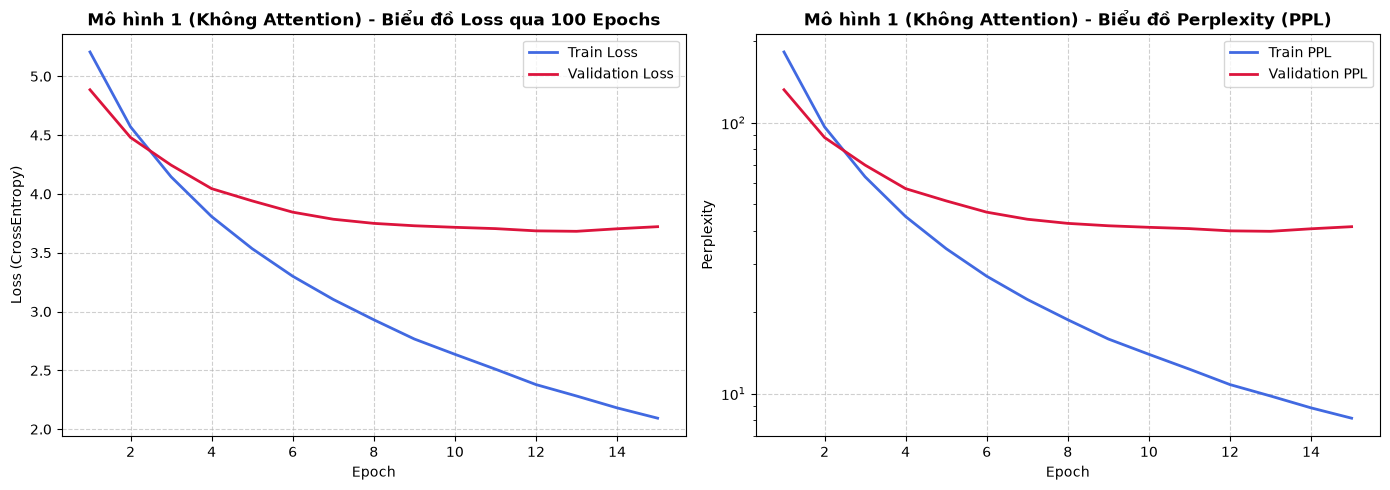

In [40]:
# =====================================================================
# CELL HUẤN LUYỆN 1: SEQ2SEQ KHÔNG CÓ ATTENTION (100 EPOCHS)
# =====================================================================
import math
import time

# 1. Cấu hình Loss và Optimizer cho Mô hình 1
criterion_no_attn = nn.CrossEntropyLoss(ignore_index=vocab_vi.PAD_IDX)
optimizer_no_attn = torch.optim.Adam(model_no_attn.parameters(), lr=1e-3)
scheduler_no_attn = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_no_attn, mode='min', factor=0.5, patience=3
)

# 2. Hàm train 1 Epoch cho Mô hình 1
def train_epoch_no_attn(model, dataloader, optimizer, criterion, clip=1.0, teacher_forcing_ratio=0.5):
    model.train()
    epoch_loss = 0

    for src, tgt in dataloader:
        src = src.to(device)
        tgt = tgt.to(device)

        optimizer.zero_grad()
        
        # Forward pass: [batch_size, tgt_len, output_dim]
        output = model(src, tgt, teacher_forcing_ratio=teacher_forcing_ratio)

        # Bỏ token <sos> ở vị trí 0 khi tính loss
        output_dim = output.shape[-1]
        output_flat = output[:, 1:].contiguous().view(-1, output_dim)
        tgt_flat = tgt[:, 1:].contiguous().view(-1)

        loss = criterion(output_flat, tgt_flat)
        loss.backward()

        # Kẹp gradient chống bùng nổ (Exploding Gradients)
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)

        optimizer.step()
        epoch_loss += loss.item()

    return epoch_loss / len(dataloader)

# 3. Hàm đánh giá (Validation) cho Mô hình 1
def evaluate_no_attn(model, dataloader, criterion):
    model.eval()
    epoch_loss = 0

    with torch.no_grad():
        for src, tgt in dataloader:
            src = src.to(device)
            tgt = tgt.to(device)

            # Tắt Teacher Forcing khi đánh giá (luôn dùng từ mô hình tự đoán)
            output = model(src, tgt, teacher_forcing_ratio=0.0)

            output_dim = output.shape[-1]
            output_flat = output[:, 1:].contiguous().view(-1, output_dim)
            tgt_flat = tgt[:, 1:].contiguous().view(-1)

            loss = criterion(output_flat, tgt_flat)
            epoch_loss += loss.item()

    return epoch_loss / len(dataloader)

# 4. Vòng lặp huấn luyện 100 Epochs cho Mô hình 1
N_EPOCHS_1 = 15
CLIP = 1.0
best_valid_loss_no_attn = float('inf')
model_save_path_no_attn = "best_model_no_attn.pt"

train_losses_no_attn = []
val_losses_no_attn = []
train_ppls_no_attn = []
val_ppls_no_attn = []

print("🚀 BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 1 (SEQ2SEQ KHÔNG ATTENTION) - 100 EPOCHS...")
print("=" * 70)

for epoch in range(N_EPOCHS_1):
    start_time = time.time()

    # Huấn luyện & Đánh giá
    train_loss = train_epoch_no_attn(model_no_attn, train_loader, optimizer_no_attn, criterion_no_attn, clip=CLIP, teacher_forcing_ratio=0.5)
    val_loss = evaluate_no_attn(model_no_attn, val_loader, criterion_no_attn)
    
    # Cập nhật Learning Rate Scheduler
    scheduler_no_attn.step(val_loss)

    elapsed_time = time.time() - start_time
    mins = int(elapsed_time // 60)
    secs = int(elapsed_time % 60)

    # Tính chỉ số Perplexity (PPL = e^Loss)
    train_ppl = math.exp(min(train_loss, 50))
    val_ppl = math.exp(min(val_loss, 50))

    train_losses_no_attn.append(train_loss)
    val_losses_no_attn.append(val_loss)
    train_ppls_no_attn.append(train_ppl)
    val_ppls_no_attn.append(val_ppl)

    # Lưu lại Checkpoint tốt nhất
    if val_loss < best_valid_loss_no_attn:
        best_valid_loss_no_attn = val_loss
        torch.save(model_no_attn.state_dict(), model_save_path_no_attn)
        saved_mark = "⭐ [Đã lưu Best Model]"
    else:
        saved_mark = ""

    current_lr = optimizer_no_attn.param_groups[0]['lr']
    print(f"Epoch: {epoch+1:03d}/{N_EPOCHS_1:03d} | Thời gian: {mins:02d}m{secs:02d}s | LR: {current_lr:.1e}")
    print(f"   Train Loss: {train_loss:.4f} (PPL: {train_ppl:7.2f}) | Val Loss: {val_loss:.4f} (PPL: {val_ppl:7.2f}) {saved_mark}")

print("=" * 70)
print(f"🎉 Hoàn thành huấn luyện Mô hình 1! Best Val Loss: {best_valid_loss_no_attn:.4f}")

# 5. Vẽ biểu đồ đánh giá tiến trình huấn luyện của Mô hình 1
plt.figure(figsize=(14, 5))

# Đồ thị Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, N_EPOCHS_1 + 1), train_losses_no_attn, label='Train Loss', color='royalblue', linewidth=2)
plt.plot(range(1, N_EPOCHS_1 + 1), val_losses_no_attn, label='Validation Loss', color='crimson', linewidth=2)
plt.title('Mô hình 1 (Không Attention) - Biểu đồ Loss qua 100 Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss (CrossEntropy)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Đồ thị Perplexity
plt.subplot(1, 2, 2)
plt.plot(range(1, N_EPOCHS_1 + 1), train_ppls_no_attn, label='Train PPL', color='royalblue', linewidth=2)
plt.plot(range(1, N_EPOCHS_1 + 1), val_ppls_no_attn, label='Validation PPL', color='crimson', linewidth=2)
plt.title('Mô hình 1 (Không Attention) - Biểu đồ Perplexity (PPL)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.yscale('log')  # Dùng thang log để hiển thị PPL rõ ràng
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 10. Huấn luyện Mô hình 2: Seq2Seq CÓ Attention (100 Epochs)

### ⚙️ Thiết lập huấn luyện:
* **Hàm mất mát (Loss):** `CrossEntropyLoss(ignore_index=vocab_vi.PAD_IDX)` — Tương tự mô hình 1 để đảm bảo tính công bằng khi so sánh.
* **Tối ưu hóa (Optimizer):** `Adam(lr=5e-4)` — Tốc độ học nhỏ hơn một chút để cơ chế Attention hội tụ mịn và ổn định hơn.
* **Kẹp Gradient (`clip_grad_norm_ = 1.0`):** Bảo vệ các trọng số GRU và các lớp Attention Projection.
* **Tiêu chí lưu mô hình:** Tự động lưu checkpoint `best_model_with_attn.pt` tại epoch có `val_loss` thấp nhất.
* **Trực quan hóa:** Tự động vẽ biểu đồ **Loss** và **Perplexity (PPL)** sau khi huấn luyện xong 100 epochs.


🚀 BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 2 (SEQ2SEQ CÓ ATTENTION) - 100 EPOCHS...
Epoch: 001/005 | Thời gian: 00m33s | LR: 5.0e-04
   Train Loss: 4.4293 (PPL:   83.87) | Val Loss: 3.7997 (PPL:   44.69) ⭐ [Đã lưu Best Model]
Epoch: 002/005 | Thời gian: 00m39s | LR: 5.0e-04
   Train Loss: 3.1832 (PPL:   24.12) | Val Loss: 3.3500 (PPL:   28.50) ⭐ [Đã lưu Best Model]
Epoch: 003/005 | Thời gian: 00m39s | LR: 5.0e-04
   Train Loss: 2.6022 (PPL:   13.49) | Val Loss: 3.1675 (PPL:   23.75) ⭐ [Đã lưu Best Model]
Epoch: 004/005 | Thời gian: 00m39s | LR: 5.0e-04
   Train Loss: 2.2480 (PPL:    9.47) | Val Loss: 3.1272 (PPL:   22.81) ⭐ [Đã lưu Best Model]
Epoch: 005/005 | Thời gian: 00m39s | LR: 5.0e-04
   Train Loss: 1.9893 (PPL:    7.31) | Val Loss: 3.1396 (PPL:   23.09) 
🎉 Hoàn thành huấn luyện Mô hình 2! Best Val Loss: 3.1272


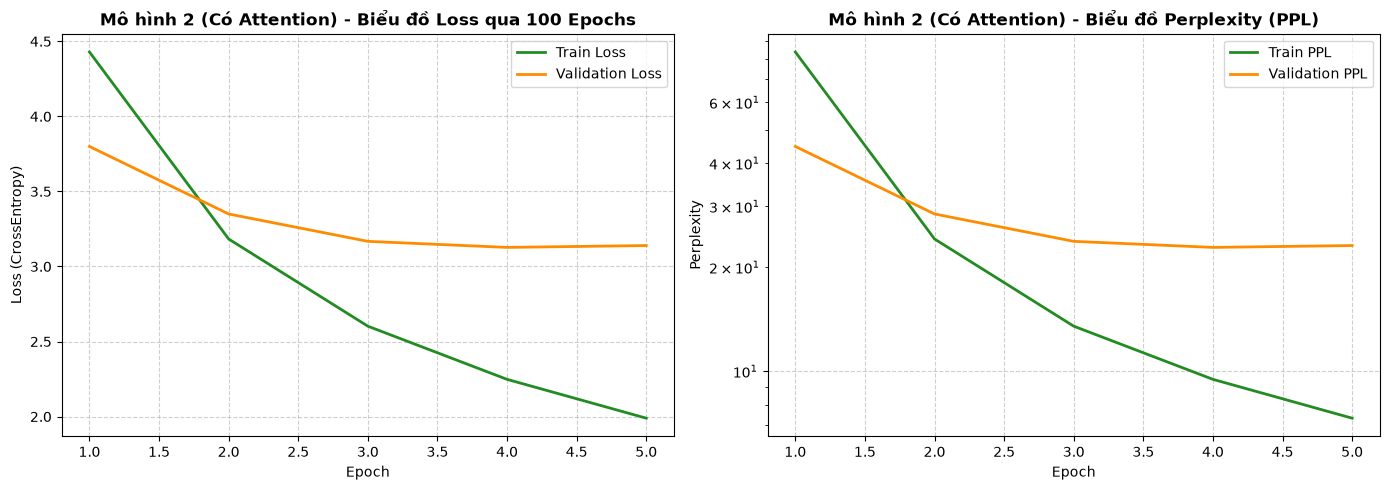

In [41]:
# =====================================================================
# CELL HUẤN LUYỆN 2: SEQ2SEQ CÓ ATTENTION (100 EPOCHS)
# =====================================================================

# 1. Cấu hình Loss và Optimizer cho Mô hình 2
criterion_with_attn = nn.CrossEntropyLoss(ignore_index=vocab_vi.PAD_IDX)
optimizer_with_attn = torch.optim.Adam(model_with_attn.parameters(), lr=5e-4)
scheduler_with_attn = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_with_attn, mode='min', factor=0.5, patience=3
)

# 2. Hàm train 1 Epoch cho Mô hình 2
def train_epoch_with_attn(model, dataloader, optimizer, criterion, clip=1.0, teacher_forcing_ratio=0.5):
    model.train()
    epoch_loss = 0

    for src, tgt in dataloader:
        src = src.to(device)
        tgt = tgt.to(device)

        optimizer.zero_grad()

        # Forward pass qua Seq2Seq with Attention
        output = model(src, tgt, teacher_forcing_ratio=teacher_forcing_ratio)

        output_dim = output.shape[-1]
        output_flat = output[:, 1:].contiguous().view(-1, output_dim)
        tgt_flat = tgt[:, 1:].contiguous().view(-1)

        loss = criterion(output_flat, tgt_flat)
        loss.backward()

        # Kẹp gradient
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)

        optimizer.step()
        epoch_loss += loss.item()

    return epoch_loss / len(dataloader)

# 3. Hàm đánh giá (Validation) cho Mô hình 2
def evaluate_with_attn(model, dataloader, criterion):
    model.eval()
    epoch_loss = 0

    with torch.no_grad():
        for src, tgt in dataloader:
            src = src.to(device)
            tgt = tgt.to(device)

            output = model(src, tgt, teacher_forcing_ratio=0.0)

            output_dim = output.shape[-1]
            output_flat = output[:, 1:].contiguous().view(-1, output_dim)
            tgt_flat = tgt[:, 1:].contiguous().view(-1)

            loss = criterion(output_flat, tgt_flat)
            epoch_loss += loss.item()

    return epoch_loss / len(dataloader)

# 4. Vòng lặp huấn luyện 100 Epochs cho Mô hình 2
N_EPOCHS_2 = 5
CLIP = 1.0
best_valid_loss_with_attn = float('inf')
model_save_path_with_attn = "best_model_with_attn.pt"

train_losses_with_attn = []
val_losses_with_attn = []
train_ppls_with_attn = []
val_ppls_with_attn = []

print("🚀 BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH 2 (SEQ2SEQ CÓ ATTENTION) - 100 EPOCHS...")
print("=" * 70)

for epoch in range(N_EPOCHS_2):
    start_time = time.time()

    train_loss = train_epoch_with_attn(model_with_attn, train_loader, optimizer_with_attn, criterion_with_attn, clip=CLIP, teacher_forcing_ratio=0.5)
    val_loss = evaluate_with_attn(model_with_attn, val_loader, criterion_with_attn)

    scheduler_with_attn.step(val_loss)

    elapsed_time = time.time() - start_time
    mins = int(elapsed_time // 60)
    secs = int(elapsed_time % 60)

    train_ppl = math.exp(min(train_loss, 50))
    val_ppl = math.exp(min(val_loss, 50))

    train_losses_with_attn.append(train_loss)
    val_losses_with_attn.append(val_loss)
    train_ppls_with_attn.append(train_ppl)
    val_ppls_with_attn.append(val_ppl)

    # Lưu lại Checkpoint tốt nhất
    if val_loss < best_valid_loss_with_attn:
        best_valid_loss_with_attn = val_loss
        torch.save(model_with_attn.state_dict(), model_save_path_with_attn)
        saved_mark = "⭐ [Đã lưu Best Model]"
    else:
        saved_mark = ""

    current_lr = optimizer_with_attn.param_groups[0]['lr']
    print(f"Epoch: {epoch+1:03d}/{N_EPOCHS_2:03d} | Thời gian: {mins:02d}m{secs:02d}s | LR: {current_lr:.1e}")
    print(f"   Train Loss: {train_loss:.4f} (PPL: {train_ppl:7.2f}) | Val Loss: {val_loss:.4f} (PPL: {val_ppl:7.2f}) {saved_mark}")

print("=" * 70)
print(f"🎉 Hoàn thành huấn luyện Mô hình 2! Best Val Loss: {best_valid_loss_with_attn:.4f}")

# 5. Vẽ biểu đồ đánh giá tiến trình huấn luyện của Mô hình 2
plt.figure(figsize=(14, 5))

# Đồ thị Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, N_EPOCHS_2 + 1), train_losses_with_attn, label='Train Loss', color='forestgreen', linewidth=2)
plt.plot(range(1, N_EPOCHS_2 + 1), val_losses_with_attn, label='Validation Loss', color='darkorange', linewidth=2)
plt.title('Mô hình 2 (Có Attention) - Biểu đồ Loss qua 100 Epochs', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss (CrossEntropy)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Đồ thị Perplexity
plt.subplot(1, 2, 2)
plt.plot(range(1, N_EPOCHS_2 + 1), train_ppls_with_attn, label='Train PPL', color='forestgreen', linewidth=2)
plt.plot(range(1, N_EPOCHS_2 + 1), val_ppls_with_attn, label='Validation PPL', color='darkorange', linewidth=2)
plt.title('Mô hình 2 (Có Attention) - Biểu đồ Perplexity (PPL)', fontsize=12, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Perplexity')
plt.yscale('log')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 11. Biểu đồ So sánh Trực quan Giữa 2 Mô hình (So sánh Loss & Perplexity)
Sau khi bạn chạy xong cả 2 cell huấn luyện phía trên, hãy chạy cell này để đặt đồ thị của cả 2 mô hình lên cùng một khung hình để so sánh trực quan hiệu quả của cơ chế **Attention**.


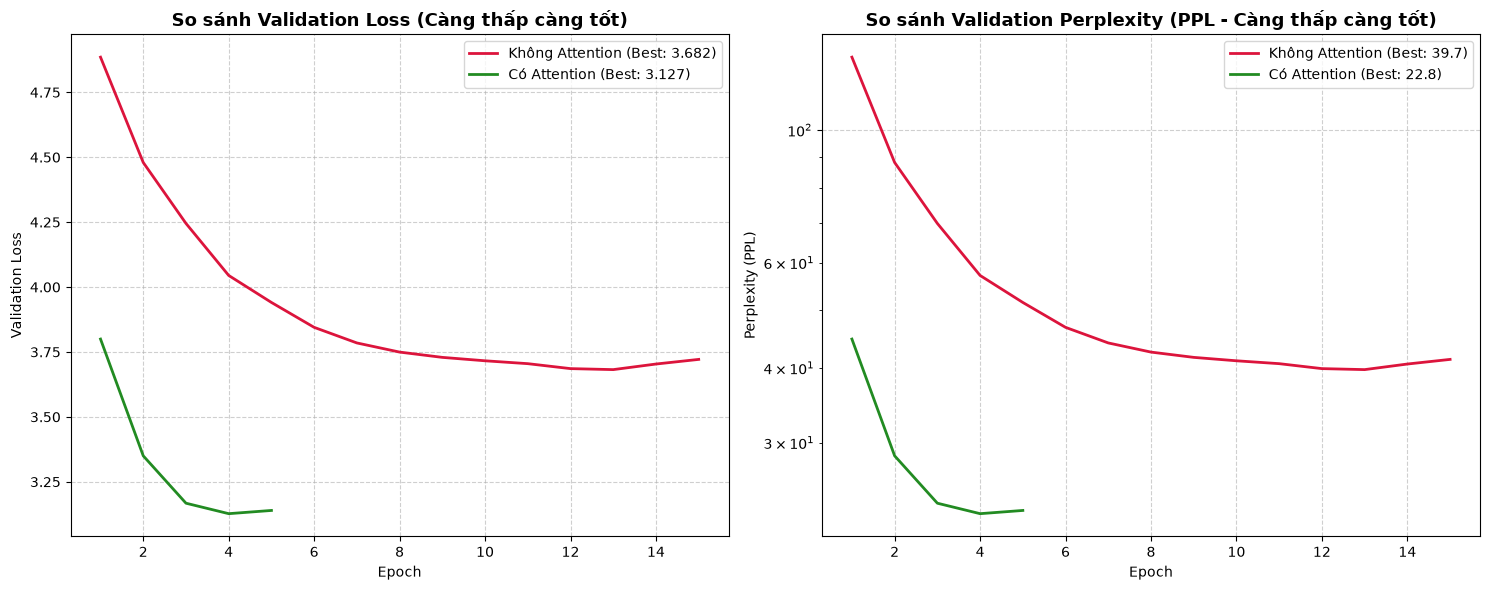

🏆 BẢNG TỔNG KẾT KẾT QUẢ CUỐI CÙNG SAU 100 EPOCHS:
🔹 Mô hình 1 (Không Attention) : Best Val Loss = 3.6820 | Best PPL = 39.73
🔹 Mô hình 2 (Có Attention)    : Best Val Loss = 3.1272 | Best PPL = 22.81


In [42]:
# =====================================================================
# BIỂU ĐỒ ĐỐI CHIẾU HIỆU SUẤT TRỰC QUAN GIỮA 2 MÔ HÌNH
# =====================================================================
plt.figure(figsize=(15, 6))

# 1. So sánh Validation Loss
plt.subplot(1, 2, 1)
if 'val_losses_no_attn' in locals() and len(val_losses_no_attn) > 0:
    plt.plot(range(1, len(val_losses_no_attn) + 1), val_losses_no_attn, label=f'Không Attention (Best: {min(val_losses_no_attn):.3f})', color='crimson', linewidth=2)
if 'val_losses_with_attn' in locals() and len(val_losses_with_attn) > 0:
    plt.plot(range(1, len(val_losses_with_attn) + 1), val_losses_with_attn, label=f'Có Attention (Best: {min(val_losses_with_attn):.3f})', color='forestgreen', linewidth=2)

plt.title('So sánh Validation Loss (Càng thấp càng tốt)', fontsize=13, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# 2. So sánh Validation Perplexity (PPL)
plt.subplot(1, 2, 2)
if 'val_ppls_no_attn' in locals() and len(val_ppls_no_attn) > 0:
    plt.plot(range(1, len(val_ppls_no_attn) + 1), val_ppls_no_attn, label=f'Không Attention (Best: {min(val_ppls_no_attn):.1f})', color='crimson', linewidth=2)
if 'val_ppls_with_attn' in locals() and len(val_ppls_with_attn) > 0:
    plt.plot(range(1, len(val_ppls_with_attn) + 1), val_ppls_with_attn, label=f'Có Attention (Best: {min(val_ppls_with_attn):.1f})', color='forestgreen', linewidth=2)

plt.title('So sánh Validation Perplexity (PPL - Càng thấp càng tốt)', fontsize=13, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Perplexity (PPL)')
plt.yscale('log')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# In bảng tổng kết số liệu
print("=" * 65)
print("🏆 BẢNG TỔNG KẾT KẾT QUẢ CUỐI CÙNG SAU 100 EPOCHS:")
print("=" * 65)
if 'best_valid_loss_no_attn' in locals():
    print(f"🔹 Mô hình 1 (Không Attention) : Best Val Loss = {best_valid_loss_no_attn:.4f} | Best PPL = {math.exp(best_valid_loss_no_attn):.2f}")
if 'best_valid_loss_with_attn' in locals():
    print(f"🔹 Mô hình 2 (Có Attention)    : Best Val Loss = {best_valid_loss_with_attn:.4f} | Best PPL = {math.exp(best_valid_loss_with_attn):.2f}")
print("=" * 65)


## 12. Thử Nghiệm Dịch Thực Tế (Inference / Translation Demo)
Hàm dịch câu tiếng Anh sang tiếng Việt sử dụng thuật toán **Greedy Search (sinh từ tuần tự)**.
Chúng ta sẽ nạp trọng số tốt nhất (`best_model_no_attn.pt` và `best_model_with_attn.pt`) để đối chiếu kết quả dịch của cả 2 mô hình.


In [43]:
# =====================================================================
# HÀM SUY LUẬN & DỊCH THỬ NGHIỆM CÂU TIẾNG ANH (INFERENCE)
# =====================================================================

# 1. Nạp lại trọng số tốt nhất của 2 mô hình
model_no_attn.load_state_dict(torch.load("best_model_no_attn.pt", map_location=device))
model_with_attn.load_state_dict(torch.load("best_model_with_attn.pt", map_location=device))

model_no_attn.eval()
model_with_attn.eval()

# 2. Hàm dịch cho Mô hình 1 (Không Attention)
def translate_no_attn(sentence, model, vocab_src, vocab_tgt, max_len=30):
    model.eval()
    tokens = vocab_src.tokenize(sentence)
    indices = [vocab_src.SOS_IDX] + [vocab_src.word2idx.get(t, vocab_src.UNK_IDX) for t in tokens] + [vocab_src.EOS_IDX]
    src_tensor = torch.tensor(indices, dtype=torch.long).unsqueeze(0).to(device)

    with torch.no_grad():
        hidden, cell = model.encoder(src_tensor)

    trg_indices = [vocab_tgt.SOS_IDX]
    for _ in range(max_len):
        prev_token = torch.tensor([trg_indices[-1]], dtype=torch.long).to(device)
        with torch.no_grad():
            output, hidden, cell = model.decoder(prev_token, hidden, cell)
        
        pred_token = output.argmax(1).item()
        if pred_token == vocab_tgt.EOS_IDX:
            break
        trg_indices.append(pred_token)

    return vocab_tgt.decode(trg_indices)

# 3. Hàm dịch cho Mô hình 2 (Có Attention)
def translate_with_attn(sentence, model, vocab_src, vocab_tgt, max_len=30):
    model.eval()
    tokens = vocab_src.tokenize(sentence)
    indices = [vocab_src.SOS_IDX] + [vocab_src.word2idx.get(t, vocab_src.UNK_IDX) for t in tokens] + [vocab_src.EOS_IDX]
    src_tensor = torch.tensor(indices, dtype=torch.long).unsqueeze(0).to(device)

    with torch.no_grad():
        encoder_states, decoder_hidden = model.encoder(src_tensor)

    trg_indices = [vocab_tgt.SOS_IDX]
    for _ in range(max_len):
        prev_token = torch.tensor([trg_indices[-1]], dtype=torch.long).to(device)
        with torch.no_grad():
            output, decoder_hidden = model.decoder(prev_token, decoder_hidden, encoder_states)

        pred_token = output.argmax(1).item()
        if pred_token == vocab_tgt.EOS_IDX:
            break
        trg_indices.append(pred_token)

    return vocab_tgt.decode(trg_indices)

# 4. Danh sách các câu mẫu để kiểm tra
test_sentences = [
   "Every evening, I usually spend about thirty minutes reading a novel before going to bed."
]

print("=" * 80)
print(f"{'CÂU TIẾNG ANH (EN)':<35} | {'MÔ HÌNH KHÔNG ATTENTION':<20} | {'MÔ HÌNH CÓ ATTENTION'}")
print("=" * 80)

for sent in test_sentences:
    trans_1 = translate_no_attn(sent, model_no_attn, vocab_en, vocab_vi)
    trans_2 = translate_with_attn(sent, model_with_attn, vocab_en, vocab_vi)
    print(f"{sent:<35} | {trans_1:<20} | {trans_2}")

print("=" * 80)


CÂU TIẾNG ANH (EN)                  | MÔ HÌNH KHÔNG ATTENTION | MÔ HÌNH CÓ ATTENTION
Every evening, I usually spend about thirty minutes reading a novel before going to bed. | mỗi hôm , , tôi đã được vài vài vài giờ . giờ . | mỗi , , tôi cũng nói chuyện .
